In [44]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
import os
from tqdm import tqdm

In [45]:
rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_specy.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])

In [46]:
rebecca_data_raman.shape, rebecca_data_ir.shape

((306, 1577), (231, 539))

In [47]:
np.unique(rebecca_data_raman['polymer'])

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype=object)

In [80]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

notes_mix_std_fluor = pd.read_excel('data_new/MVCP_20241206_RP_AllCCOPTIRData_FluorescenceOnly.xlsx',
         sheet_name='MPs + Standards').iloc[:, [0,9,10,11,12]]
notes_mix_std_fluor.columns = ['id','polymer_ir', 'polymer_raman', 'polymer_overall', 'comments']
notes_mix_std_fluor = notes_mix_std_fluor.query('polymer_overall in @poly_list')
notes_mix_std_fluor_ids = np.array(notes_mix_std_fluor['id'])


IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-8])) + list(IR_spectra_mix_std.columns[-8:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix_std = IR_spectra_mix_std.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca.csv')
Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_specy.csv')
#notes_mix_std_rest = np.array(Raman_spectra_mix_std['comments'])
notes_mix_std = Raman_spectra_mix_std.iloc[:,-5:]

notes_mix_std = (notes_mix_std.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix_std.loc[notes_mix_std['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_std_rest[[x is np.nan for x in notes_mix_std_rest]] = ''
del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.sort_values('id').reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
notes_mix_std_rest = notes_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'

ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix_std['polymer_raman'], notes_mix_std['polymer_ir'], notes_mix_std['polymer_overall'])]
ids_ideal_set = np.logical_and([x not in notes_mix_std_fluor_ids for x in Raman_spectra_mix_std['id']],
                               ids_ideal_set)

Raman_spectra_mix_std['id'] = ["mix_std_"+str(x) for x in Raman_spectra_mix_std['id']]
IR_spectra_mix_std['id'] = ["mix_std_"+str(x) for x in IR_spectra_mix_std['id']]

Raman_spectra_mix_std_ideal = Raman_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)
IR_spectra_mix_std_ideal = IR_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)

Raman_spectra_mix_std_lq = Raman_spectra_mix_std.loc[~ids_ideal_set,:].reset_index(drop=True)
IR_spectra_mix_std_lq = IR_spectra_mix_std.loc[~ids_ideal_set,:].reset_index(drop=True)

Raman_spectra_mix_std_lq = Raman_spectra_mix_std_lq.query('id != "mix_std_223"').reset_index(drop=True)
IR_spectra_mix_std_lq = IR_spectra_mix_std_lq.query('id != "mix_std_223"').reset_index(drop=True)


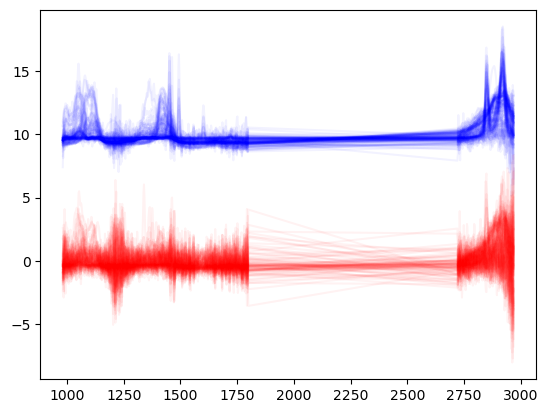

In [81]:
_ = plt.plot(10+IR_spectra_mix_std_ideal.iloc[:,:-8].T,c='b',alpha=.05)
_ = plt.plot(IR_spectra_mix_std_lq.iloc[:,:-8].T,c='r',alpha=.05)

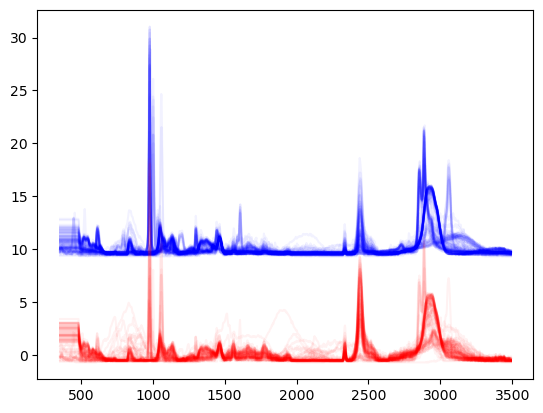

In [82]:
_ = plt.plot(10+Raman_spectra_mix_std_ideal.iloc[:,:-8].T,c='b',alpha=.05)
_ = plt.plot(Raman_spectra_mix_std_lq.iloc[:,:-8].T,c='r',alpha=.05)

In [83]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

notes_mix_fluor = pd.read_excel('data_new/MVCP_20241206_RP_AllCCOPTIRData_FluorescenceOnly.xlsx',
         sheet_name='MPs Only').iloc[:, [0,9,10,11,12]]
notes_mix_fluor.columns = ['id','polymer_ir', 'polymer_raman', 'polymer_overall', 'comments']
notes_mix_fluor = notes_mix_fluor.query('polymer_overall in @poly_list')
notes_mix_fluor_ids = np.array(notes_mix_fluor['id'])


IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-8])) + list(IR_spectra_mix.columns[-8:])

IR_spectra_mix = (IR_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix = IR_spectra_mix.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca.csv')
Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_specy.csv')
#notes_mix_rest = np.array(Raman_spectra_mix['comments'])
notes_mix = Raman_spectra_mix.iloc[:,-5:]

notes_mix = (notes_mix.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix.loc[notes_mix['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix.loc[notes_mix['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix.loc[notes_mix['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_rest[[x is np.nan for x in notes_mix_rest]] = ''
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-7])) + list(Raman_spectra_mix.columns[-7:])
Raman_spectra_mix = (Raman_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.sort_values('id').reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
notes_mix_rest = notes_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'

ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix['polymer_raman'], notes_mix['polymer_ir'], notes_mix['polymer_overall'])]
ids_ideal_set = np.logical_and([x not in notes_mix_fluor_ids for x in Raman_spectra_mix['id']],
                               ids_ideal_set)

Raman_spectra_mix['id'] = ["mix_"+str(x) for x in Raman_spectra_mix['id']]
IR_spectra_mix['id'] = ["mix_"+str(x) for x in IR_spectra_mix['id']]

Raman_spectra_mix_ideal = Raman_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)
IR_spectra_mix_ideal = IR_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)

Raman_spectra_mix_lq = Raman_spectra_mix.loc[~ids_ideal_set,:].reset_index(drop=True)
IR_spectra_mix_lq = IR_spectra_mix.loc[~ids_ideal_set,:].reset_index(drop=True)


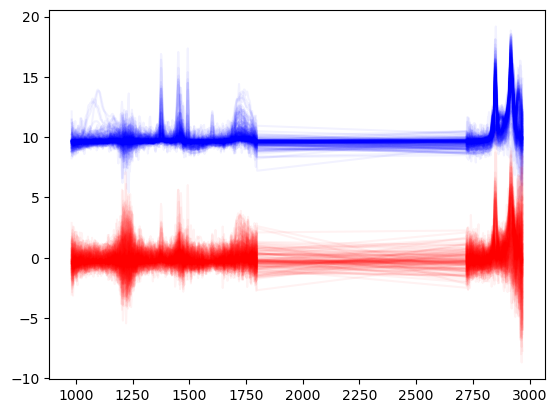

In [84]:
_ = plt.plot(10+IR_spectra_mix_ideal.iloc[:,:-8].T,c='b',alpha=.05)
_ = plt.plot(IR_spectra_mix_lq.iloc[:,:-8].T,c='r',alpha=.05)

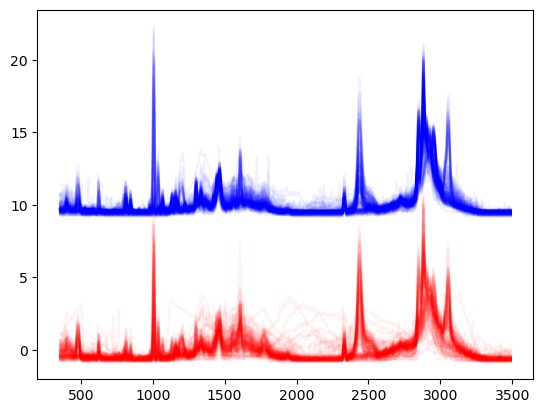

In [85]:
_ = plt.plot(10+Raman_spectra_mix_ideal.iloc[:,:-8].T,c='b',alpha=.05)
_ = plt.plot(Raman_spectra_mix_lq.iloc[:,:-8].T,c='r',alpha=.05)

In [86]:
def process_data(rebecca_data_ir, rebecca_data_raman, IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 
    
    wn_rb = np.array(rebecca_data_ir.columns[:-4])
    idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                           np.logical_and(wn_rb > 2720, wn_rb < 2950)
                          ) ) + [False]*4
    
    wn_rb_r = np.array(rebecca_data_raman.columns[:-4])
    idx_rb_r = list(np.logical_and(wn_rb_r > range_r[0], wn_rb_r < range_r[1])) + [False]*4


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4
    
    x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
    x_train_ir = (x_train_ir - x_train_ir.mean(1)[:, None]) / x_train_ir.std(1)[:, None]
    
    y_train_ir = rebecca_data_ir.iloc[:,-2]

    x_train_raman = rebecca_data_raman.iloc[:,idx_rb_r].to_numpy()
    x_train_raman = (x_train_raman - x_train_raman.mean(1)[:, None]) / x_train_raman.std(1)[:, None]
    
    y_train_raman = rebecca_data_raman.iloc[:,-2]

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]
    y_test = IR_spectra.iloc[:,-3]
    
    idx_test = np.sum(np.isnan(x_raman), axis=1) == 0
    
    x_ir = x_ir[idx_test,:]
    x_raman = x_raman[idx_test,:]
    
    y_raman = y_test[idx_test]
    y_ir = y_test[idx_test]
    
    #y_test[y_test == 'LDPE'] = 'PE'
    
    poly_list = list(np.unique(np.concatenate([y_train_ir, y_train_raman, y_ir]))) 
    label_table = pd.DataFrame({'label':np.arange(len(poly_list)), 'polymer':poly_list})
    
    label_train_Raman = np.array(pd.DataFrame(y_train_raman).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    label_train_IR = np.array(pd.DataFrame(y_train_ir).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    
    label_ir = np.array(pd.DataFrame(y_ir).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    label_raman = np.array(pd.DataFrame(y_raman).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    return x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table


In [87]:
def process_data_2(IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]

    y_test = IR_spectra.iloc[:,-3]
    #y_test[y_test == 'LDPE'] = 'PE'
    
    return x_ir, x_raman, y_test

In [88]:
def experiment(score_list, label_ir, quality, alphas, N_sim, quant_prop=.2, cal_prop=.8, seed_init=0):
    df_res_lis = []
    df_res_sd_lis = []
    df_res_all_lis = []
    df_res_cov_lis = []
    df_res_cov_sd_lis = []
    
    df_res_cov_all_lis = []
    df_res_all_mean_lis = []
    df_res_cov_all_mean_lis = []
    

    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_all = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)        
        
        K = 2
        U_list = gen_u(K, seed=0)
        seed = seed_init
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=quant_prop, seed=seed)
                quality_quant = quality[idx_quant]
                quality_rest = quality[~idx_quant]

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=cal_prop, seed=seed)
                
                quality_cal = quality_rest[idx]
                quality_val = quality_rest[~idx]
                
                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]
            #n = quant_labels.shape[0]

            prediction_sets, empirical_coverage, _ = mvcp_2(quant_smx_list,
                                                             quant_labels,
                                                             cal_smx_list,# quant_smx_list,
                                                             cal_labels,#quant_labels,
                                                             val_smx_list,#rest_smx_list,
                                                             alpha, 
                                                             val_labels,#rest_labels,
                                                             U=U_list[0])


            set_size['mvcp_ideal'].append(
                    prediction_sets[quality_val=="ideal"].sum(1).mean()
                )
            set_size_all['mvcp_ideal'].append(
                    prediction_sets[quality_val=="ideal"].sum(1)
                )
            
            set_size['mvcp_low_ir'].append(
                    prediction_sets[quality_val=="low_ir"].sum(1).mean()
                )
            set_size_all['mvcp_low_ir'].append(
                    prediction_sets[quality_val=="low_ir"].sum(1)
                )
            
            set_size['mvcp_low_raman'].append(
                    prediction_sets[quality_val=="low_raman"].sum(1).mean()
                )
            set_size_all['mvcp_low_raman'].append(
                    prediction_sets[quality_val=="low_raman"].sum(1)
                )
            
            zero_sets['mvcp'].append(
                    np.mean(prediction_sets.sum(1) == 0)
                )
            
            
            empirical_coverage_ideal = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="ideal"])
            empirical_coverage_low_ir = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_ir"])
            empirical_coverage_low_raman = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_raman"])
            
            cov['mvcp_ideal'].append(
                    empirical_coverage_ideal
                )
            
            cov['mvcp_low_ir'].append(
                    empirical_coverage_low_ir
                )
            
            cov['mvcp_low_raman'].append(
                    empirical_coverage_low_raman
                )
            
            
            cov_all['mvcp_ideal'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="ideal"]
                )
            
            cov_all['mvcp_low_ir'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_ir"]
                )
            
            cov_all['mvcp_low_raman'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_raman"]
                )

            set_size_by_label_hqi['mvcp'].append(
                    pd.DataFrame({'label':val_labels,#rest_labels,
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

            s_u = rest_smx_list[0]
                #print(top_views[:(j+1)])
                #print(np.argmax(top_views[:(j+1)]))

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            #cal_smx, val_smx, cal_labels, val_labels = quant_smx_list[0], rest_smx_list[0], quant_labels, rest_labels
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            
            set_size['view_IR_ideal'].append(prediction_sets[quality_val=="ideal"].sum(1).mean())
            set_size['view_IR_low_ir'].append(prediction_sets[quality_val=="low_ir"].sum(1).mean())
            set_size['view_IR_low_raman'].append(prediction_sets[quality_val=="low_raman"].sum(1).mean())
            
            set_size_all['view_IR_ideal'].append(
                    prediction_sets[quality_val=="ideal"].sum(1)
                )
            set_size_all['view_IR_low_ir'].append(
                    prediction_sets[quality_val=="low_ir"].sum(1)
                )
            
            set_size_all['view_IR_low_raman'].append(
                    prediction_sets[quality_val=="low_raman"].sum(1)
                )

            zero_sets['view_IR'].append(np.mean(prediction_sets.sum(1) == 0))
            
            empirical_coverage_ideal = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="ideal"])
            empirical_coverage_low_ir = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_ir"])
            empirical_coverage_low_raman = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_raman"])
            
            cov['view_IR_ideal'].append(empirical_coverage_ideal)
            cov['view_IR_low_ir'].append(empirical_coverage_low_ir)
            cov['view_IR_low_raman'].append(empirical_coverage_low_raman)
            
            cov_all['view_IR_ideal'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="ideal"]
                )
            
            cov_all['view_IR_low_ir'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_ir"]
                )
            cov_all['view_IR_low_raman'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_raman"]
                )
            
            set_size_by_label_hqi['view_IR'].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

            s_u = rest_smx_list[1]
                #print(top_views[:(j+1)])
                #print(np.argmax(top_views[:(j+1)]))

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            #cal_smx, val_smx, cal_labels, val_labels = quant_smx_list[1], rest_smx_list[1], quant_labels, rest_labels
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            
            set_size['view_Raman_ideal'].append(prediction_sets[quality_val=="ideal"].sum(1).mean())
            set_size['view_Raman_low_ir'].append(prediction_sets[quality_val=="low_ir"].sum(1).mean())
            set_size['view_Raman_low_raman'].append(prediction_sets[quality_val=="low_raman"].sum(1).mean())
            
            set_size_all['view_Raman_ideal'].append(
                    prediction_sets[quality_val=="ideal"].sum(1)
                )
            set_size_all['view_Raman_low_ir'].append(
                    prediction_sets[quality_val=="low_ir"].sum(1)
                )
            
            set_size_all['view_Raman_low_raman'].append(
                    prediction_sets[quality_val=="low_raman"].sum(1)
                )

            zero_sets['view_Raman'].append(np.mean(prediction_sets.sum(1) == 0))
            
            empirical_coverage_ideal = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="ideal"])
            empirical_coverage_low_ir = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_ir"])
            empirical_coverage_low_raman = np.mean(prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_raman"])
            
            cov['view_Raman_ideal'].append(empirical_coverage_ideal)
            cov['view_Raman_low_ir'].append(empirical_coverage_low_ir)
            cov['view_Raman_low_raman'].append(empirical_coverage_low_raman)
            
            cov_all['view_Raman_ideal'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="ideal"]
                )
            
            cov_all['view_Raman_low_ir'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_ir"]
                )
            
            cov_all['view_Raman_low_raman'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels][quality_val=="low_raman"]
                )
            
        df_res_all_lis.append(set_size_all)
        df_res_cov_all_lis.append(cov_all)
        
        df_res_all_mean_lis.append(set_size)
        df_res_cov_all_mean_lis.append(cov)
        
        
        df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0)#.loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0)#.loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_sd_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0)#.loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).std()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0)#.loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_sd_lis.append(df_res)

    return df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_mean_lis, df_res_cov_all_mean_lis, df_res_all_lis, df_res_cov_all_lis
    

In [89]:
def envelop(score_list, label_ir, score_example, alphas, N_sim=1, quant_prop=.2, cal_prop=.8, seed_init=0):
    env_list = defaultdict(list)
    ps_list = defaultdict(list)
    ps_ir_list = defaultdict(list)
    ps_raman_list = defaultdict(list)
    q_ir_list = defaultdict(list)
    q_raman_list = defaultdict(list)
        
    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)
        K = 2
        U_list = gen_u(K, n_th=400, seed=0)
        seed = seed_init
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=quant_prop, seed=seed)
                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=cal_prop, seed=seed)
                

                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]
            #n = quant_labels.shape[0]

            prediction_sets, U_quant_env = mvcp_2(quant_smx_list,
                                                             quant_labels,
                                                             cal_smx_list, #quant_smx_list,
                                                             cal_labels, #quant_labels,
                                                             score_example,#val_smx_list, #rest_smx_list, 
                                                             alpha, 
                                                             val_labels=None, #rest_labels,
                                                             U=U_list[0])

            
            s_u = rest_smx_list[0]

            cal_ir_smx, val_ir_smx, cal_ir_labels, val_ir_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            n = cal_ir_smx.shape[0]
            prediction_sets_ir, qhat_ir = conform_prediction(cal_ir_smx, score_example[0], cal_ir_labels, n, alpha, val_labels=None, cond=0)

            s_u = rest_smx_list[1]

            cal_raman_smx, val_raman_smx, cal_raman_labels, val_raman_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            n = cal_raman_smx.shape[0]
            prediction_sets_raman, qhat_raman = conform_prediction(cal_raman_smx, score_example[1], cal_raman_labels, n, alpha, val_labels=None, cond=0)            

            
            ps_ir_list[int(100*alpha)].append(list(label_table.loc[prediction_sets_ir[0], 'polymer']))            
            ps_raman_list[int(100*alpha)].append(list(label_table.loc[prediction_sets_raman[0], 'polymer']))            
            ps_list[int(100*alpha)].append(list(label_table.loc[prediction_sets[0], 'polymer']))
            

            beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels, U=U_list[0])

            n = cal_smx_list[0].shape[0]
            t = np.max([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0)
            q_level = np.clip(np.ceil((n+1)*(1-alpha))/n, 0, 1)
            t_quant = np.quantile(t, q_level, method='higher')
            cal_smx_arr = np.array([cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
                                    cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels]])
            
            plt.scatter(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
                        cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels], 
                        label='calibration set')

        
            idx_quant_reg = np.argsort(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels]/t)#[::-1]
            quant_reg_x = t_quant*np.sort(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels]/t)#[::-1]
            quant_reg_y = t_quant*(cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels]/t)[idx_quant_reg]
            
            q_ir_list[int(100*alpha)].append(qhat_ir)
            q_raman_list[int(100*alpha)].append(qhat_raman)
            env_list[int(100*alpha)].append([quant_reg_x, quant_reg_y])
            
            print("MVCP", ps_list[int(100*alpha)][-1])
            print("IR", ps_ir_list[int(100*alpha)][-1])
            print("Raman", ps_raman_list[int(100*alpha)][-1])
            
            #for th in range(U_list[0].shape[0]):
            #    u = U_list[0][th]
            #    plt.scatter(u[0]*q_array[th],
            #                u[1]*q_array[th],
            #                c='yellow',
            #                s=1)
            
            #plt.scatter(U_quant_env[:,0],
            #            U_quant_env[:,1],
            #                c='green',
            #                s=1)
            
            plt.plot(quant_reg_x,
                     quant_reg_y, 
                     label=str(int(100*(1-alpha)))+' quantile region',
                     c='orange',
                     linewidth=3.0
                 )
            
            _ = plt.vlines(x= qhat_ir,
                ymin=0,
                ymax=.25,
                colors='r',
                alpha=.5,
                linestyles='solid',
                label='95 IR Quantile')

            _ = plt.hlines(y= qhat_raman,
                            xmin=0,
                            xmax=.7,
                            colors='purple',
                            alpha=.5,
                            linestyles='solid',
                            label='95 Raman Quantile')

            plt.scatter(score_example[0],
                        score_example[1], c='r')
            
            for i in range(6):
                plt.text(score_example[0][0, i], 
                         score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')

            plt.xlabel("IR 1-HQI")
            plt.ylabel("Raman 1-HQI")

            plt.legend()
            plt.show()


    

    return ps_list, ps_ir_list, ps_raman_list, env_list, cal_smx_arr, q_ir_list, q_raman_list


In [90]:
IR_spectra_all.shape

(531, 543)

In [91]:
x_ir.shape

(530, 525)

In [92]:
IR_spectra_mix_std_ideal

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
0,-0.828293,-0.758405,-0.726251,-0.765111,-0.770808,-0.728753,-0.727293,-0.757429,-0.730070,-0.732946,...,2.214848,2.194427,0,0,AS,AS,NaN,NH2SO4,mix_std_1,no_background
1,-0.163192,-0.074564,-0.230509,-0.292448,-0.220771,0.011111,0.144867,-0.239115,-0.418914,-0.141851,...,0.964838,0.918447,0,0,SCR,SCR,NaN,sucrose,mix_std_2,no_background
2,-0.687633,-0.669232,-0.665962,-0.658443,-0.664548,-0.657761,-0.636442,-0.635479,-0.632942,-0.640414,...,0.085936,0.207231,0,0,AS,AS,NaN,NH2SO4,mix_std_7,no_background
3,-0.867752,-0.859657,-0.849902,-0.856831,-0.866892,-0.864862,-0.857160,-0.851088,-0.845789,-0.839414,...,1.840057,1.914082,0,0,AS,AS,NaN,NH2SO4,mix_std_8,no_background
4,-0.410113,-0.296803,-0.217183,-0.096301,-0.001415,0.050736,0.087762,0.133790,0.176923,0.152262,...,0.828414,0.786148,0,0,SCR,SCR,NaN,sucrose,mix_std_10,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
132,-0.758620,-0.674830,-0.572468,-0.333465,-0.196565,-0.223604,-0.230819,-0.175203,-0.093618,-0.075711,...,0.959062,0.957826,0,0,SCR,SCR,NaN,sucrose,mix_std_416,no_background
133,-0.508493,-0.476967,-0.465096,-0.471244,-0.493983,-0.448887,-0.328680,-0.303054,-0.341080,-0.336764,...,1.474708,1.374374,0,0,SCR,SCR,NaN,sucrose,mix_std_417,no_background
134,-0.700983,-0.507975,-0.611709,-0.594229,-0.543882,-0.478057,-0.476607,-0.357931,-0.436148,-0.664038,...,1.333663,-0.043708,0,0,SCR,SCR,NaN,sucrose,mix_std_420,no_background
135,-0.373516,-0.376575,-0.377634,-0.371173,-0.377284,-0.377095,-0.369783,-0.372860,-0.377227,-0.376942,...,0.011794,-0.051611,0,0,LDPE,LDPE,NaN,PE,mix_std_425,no_background


In [120]:
IR_spectra_all = pd.concat([IR_spectra_mix_std_ideal, IR_spectra_mix_ideal,
                            IR_spectra_mix_std_lq, IR_spectra_mix_lq], axis=0).reset_index(drop=True)

Raman_spectra_all = pd.concat([Raman_spectra_mix_std_ideal, Raman_spectra_mix_ideal,
                               Raman_spectra_mix_std_lq, Raman_spectra_mix_lq], axis=0).reset_index(drop=True)
wn = np.array(Raman_spectra_all.columns[:-4])

x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table = process_data(rebecca_data_ir, 
                                                                                                         rebecca_data_raman, 
                                                                                                         IR_spectra_all,
                                                                                                         Raman_spectra_all)

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_rest, Raman_spectra_mix_rest)

quality = np.array(['ideal']*(IR_spectra_mix_std_ideal.shape[0] + IR_spectra_mix_ideal.shape[0])+ 
 ['low_ir']*(IR_spectra_mix_std_lq.shape[0] + IR_spectra_mix_lq.shape[0]))

smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

#smx_all_IR_all = 1-np.power(smx_nn_all(x_train_ir, x_ir, label_train_IR),1)
#smx_all_Raman_all = 1-np.power(smx_nn_all(x_train_raman, x_raman, label_train_Raman),1)
#score_list_all = [smx_all_IR_all, smx_all_Raman_all]


print(np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman))
print(np.nanmean(np.argmin(score_list[0][quality=='ideal'], 1) == label_ir[quality=='ideal']), np.nanmean(np.argmin(score_list[1][quality=='ideal'], 1) == label_raman[quality=='ideal']))
print(np.nanmean(np.argmin(score_list[0][quality=='low_ir'], 1) == label_ir[quality=='low_ir']), np.nanmean(np.argmin(score_list[1][quality=='low_ir'], 1) == label_raman[quality=='low_ir']))





#df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_lis

0.8169811320754717 0.8264150943396227
0.9314641744548287 0.9034267912772586
0.6411483253588517 0.7081339712918661


In [ ]:
(df_res_lis, 
 df_res_sd_lis,
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis, 
 df_res_all_lis, 
 df_res_cov_all_lis)  = experiment(score_list,                                      
                                   label_ir,                                   
                                   quality,
                                   alphas=[0.05],
                                   N_sim=50, 
                                   quant_prop=.2, 
                                   cal_prop=0.8, 
                                   seed_init=0)

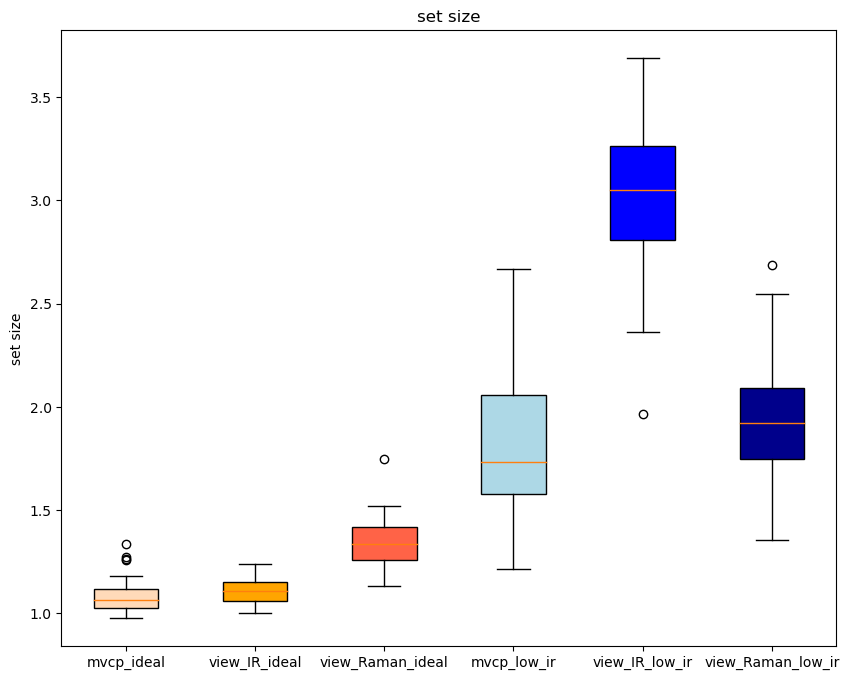

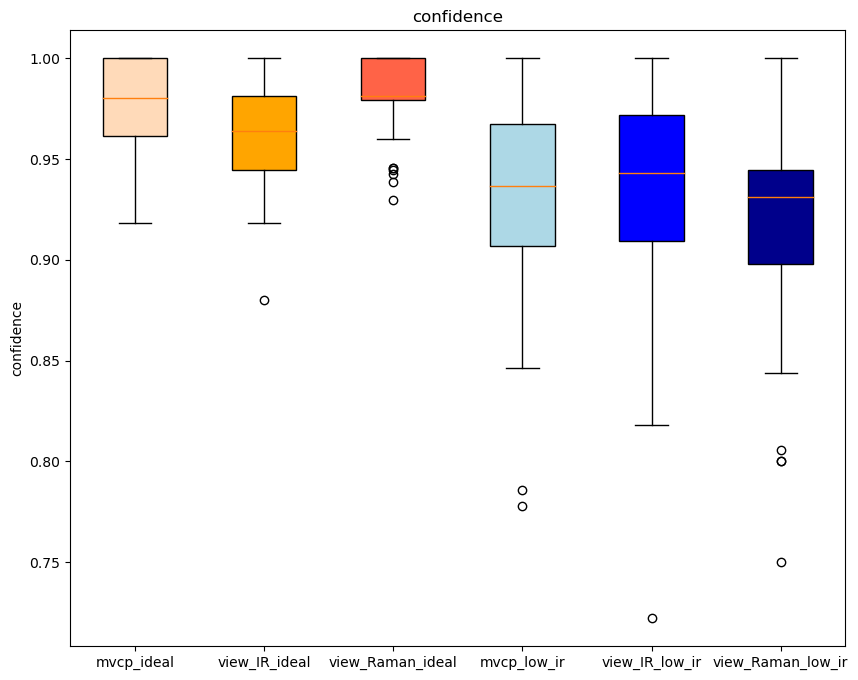

In [95]:
#labels = ['mvcp_ideal', 'view_IR_ideal', 'view_Raman_ideal', 'mvcp_low', 'view_IR_low', 'view_Raman_low']
labels = ['mvcp_ideal', 
          'view_IR_ideal', 
          'view_Raman_ideal', 
          'mvcp_low_ir', 
          'view_IR_low_ir', 
          'view_Raman_low_ir']

set_size = [np.array(df_res_all_mean_lis[0][x]) for x in labels]#df_res_all_lis[0]
#emp_conf_list.append(df_res_cov_lis)
    
fig, ax = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True, figsize=(10, 8))
title = ['none', 'low', 'medium', 'high']




#labels = list(df_res_all_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato', 'lightblue', 'blue', 'darkblue']

ax.set_ylabel('set size')
ax.set_title('set size')

bplot = ax.boxplot(set_size,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()


cov = [np.array(df_res_cov_all_mean_lis[0][x]) for x in labels]#df_res_all_lis[0]
#emp_conf_list.append(df_res_cov_lis)
    
fig, ax = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True, figsize=(10, 8))
title = ['none', 'low', 'medium', 'high']




#labels = list(df_res_all_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato', 'lightblue', 'blue', 'darkblue']

ax.set_ylabel('confidence')
ax.set_title('confidence')

bplot = ax.boxplot(cov,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()

In [183]:
set_size_df

,set size mvcp_ideal,set size view_IR_ideal,set size view_Raman_ideal,set size mvcp_low,set size view_IR_low,set size view_Raman_low
0,1.113208,1.415094,1.641509,2.281250,3.531250,2.593750
1,1.000000,1.090909,1.618182,2.500000,3.433333,2.333333
2,1.166667,1.145833,1.875000,2.432432,3.378378,3.027027
3,1.036364,1.236364,1.818182,2.833333,4.200000,2.366667
4,1.191489,1.234043,1.659574,2.342105,2.815789,2.657895
5,1.160000,1.220000,1.860000,2.771429,3.742857,2.142857
6,1.288889,1.333333,1.733333,1.925000,3.250000,2.125000
7,1.232143,1.339286,1.678571,2.482759,3.137931,3.000000
8,1.078431,1.078431,1.705882,1.970588,2.941176,2.352941
9,1.185185,1.203704,1.907407,2.193548,3.451613,2.451613


In [184]:
set_size_df = pd.DataFrame(set_size).T
set_size_df.columns = ["set size "+x[:-3] if x[-2:]=="ir" else "set size "+x for x in labels]
cov_df = pd.DataFrame(cov).T
cov_df.columns = ["confidence "+x[:-3] if x[-2:]=="ir" else "confidence "+x for x in labels]
pd.concat([set_size_df,cov_df], axis=1)#.to_csv('results/data_fig_3a.csv')

,set size mvcp_ideal,set size view_IR_ideal,set size view_Raman_ideal,set size mvcp_low,set size view_IR_low,set size view_Raman_low,confidence mvcp_ideal,confidence view_IR_ideal,confidence view_Raman_ideal,confidence mvcp_low,confidence view_IR_low,confidence view_Raman_low
0,1.113208,1.415094,1.641509,2.281250,3.531250,2.593750,0.943396,0.962264,0.943396,0.937500,1.000000,0.937500
1,1.000000,1.090909,1.618182,2.500000,3.433333,2.333333,0.945455,0.963636,0.963636,0.900000,0.933333,0.933333
2,1.166667,1.145833,1.875000,2.432432,3.378378,3.027027,1.000000,1.000000,1.000000,0.891892,0.864865,0.891892
3,1.036364,1.236364,1.818182,2.833333,4.200000,2.366667,1.000000,1.000000,1.000000,0.966667,1.000000,0.933333
4,1.191489,1.234043,1.659574,2.342105,2.815789,2.657895,0.978723,0.936170,1.000000,0.842105,0.842105,0.921053
5,1.160000,1.220000,1.860000,2.771429,3.742857,2.142857,0.960000,0.980000,0.940000,0.971429,0.914286,0.971429
6,1.288889,1.333333,1.733333,1.925000,3.250000,2.125000,0.977778,0.933333,1.000000,0.875000,0.925000,0.900000
7,1.232143,1.339286,1.678571,2.482759,3.137931,3.000000,0.946429,0.946429,0.946429,1.000000,0.931034,1.000000
8,1.078431,1.078431,1.705882,1.970588,2.941176,2.352941,0.921569,0.960784,0.901961,0.970588,0.970588,0.970588
9,1.185185,1.203704,1.907407,2.193548,3.451613,2.451613,1.000000,0.981481,1.000000,0.935484,0.903226,0.967742


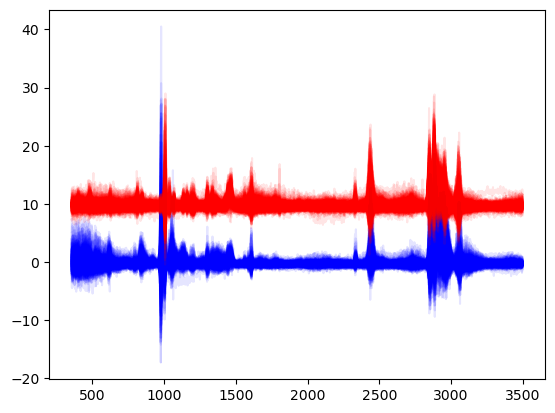

In [284]:
_ = plt.plot(Raman_spectra_mix_std_lq_sint.iloc[:,:-4].T, color='blue', alpha=.1)
_ = plt.plot(Raman_spectra_mix_lq_sint.iloc[:,:-4].T+10, color='red', alpha=.1)

In [285]:
pd.concat([Raman_spectra_mix_std_lq_sint, Raman_spectra_mix_lq_sint], axis=0).reset_index(drop=True).to_csv('results/data_fig_3a_augmented_Raman.csv')


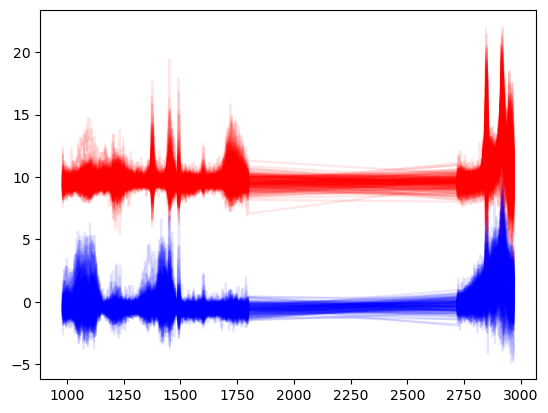

In [278]:
_ = plt.plot(IR_spectra_mix_std_lq_sint.iloc[:,:-8].T, color='blue', alpha=.1)
_ = plt.plot(IR_spectra_mix_lq_sint.iloc[:,:-8].T+10, color='red', alpha=.1)

In [282]:
pd.concat([IR_spectra_mix_std_lq_sint, IR_spectra_mix_lq_sint], axis=0).reset_index(drop=True).to_csv('results/data_fig_3a_augmented_IR.csv')


In [103]:
set_size_list = []
cov_list = []

for k in range(50):
    noise_IR = 1#1
    noise_Raman = 1#0.5
    n_ideal_mix = IR_spectra_mix_ideal.shape[0]
    n_ideal_mix_std = IR_spectra_mix_std_ideal.shape[0]
    n_ideal = n_ideal_mix_std + n_ideal_mix

    np.random.seed(k)

    idx_mix_std, idx_mix = (np.linspace(0,1,n_ideal_mix_std), 
                            np.linspace(0,1,n_ideal_mix))

    np.random.shuffle(idx_mix_std)
    np.random.shuffle(idx_mix)

    idx_ideal_mix_std, idx_ideal_mix = (idx_mix_std< 1/3, 
                                        idx_mix< 1/3)

    idx_low_ir_mix_std, idx_low_ir_mix = (np.logical_and(idx_mix_std > 1/3,
                                                         idx_mix_std < 2/3),
                                          np.logical_and(idx_mix > 1/3,
                                                         idx_mix < 2/3))

    idx_low_raman_mix_std, idx_low_raman_mix = (idx_mix_std> 2/3, 
                                                idx_mix > 2/3)

    np.random.shuffle(idx_ideal_mix_std)
    np.random.shuffle(idx_ideal_mix)

    np.random.shuffle(idx_low_ir_mix_std)
    np.random.shuffle(idx_low_ir_mix)

    np.random.shuffle(idx_ideal_mix_std)
    np.random.shuffle(idx_ideal_mix_std)


    IR_spectra_mix_std_lq_sint_ir = IR_spectra_mix_std_ideal.loc[idx_low_ir_mix_std,:].copy()
    IR_spectra_mix_std_lq_sint_raman = IR_spectra_mix_std_ideal.loc[idx_low_raman_mix_std,:].copy()

    IR_spectra_mix_lq_sint_ir = IR_spectra_mix_ideal.loc[idx_low_ir_mix,:].copy()
    IR_spectra_mix_lq_sint_raman = IR_spectra_mix_ideal.loc[idx_low_raman_mix,:].copy()

    Raman_spectra_mix_std_lq_sint_raman = Raman_spectra_mix_std_ideal.loc[idx_low_raman_mix_std,:].copy()
    Raman_spectra_mix_std_lq_sint_ir = Raman_spectra_mix_std_ideal.loc[idx_low_ir_mix_std,:].copy()

    Raman_spectra_mix_lq_sint_raman = Raman_spectra_mix_ideal.loc[idx_low_raman_mix,:].copy()
    Raman_spectra_mix_lq_sint_ir = Raman_spectra_mix_ideal.loc[idx_low_ir_mix,:].copy()

    #noise_IR_mix_std = noise_IR*np.random.normal(0,1,IR_spectra_mix_std_ideal.iloc[:,:-8].shape)
    #noise_IR_mix = noise_IR*np.random.normal(0,1,IR_spectra_mix_ideal.iloc[:,:-8].shape)

    noise_IR_mix_std = noise_IR*np.random.normal(0,
                                                 np.array(np.std(IR_spectra_mix_std_ideal.iloc[:,:-8],0)), 
                                                 size=IR_spectra_mix_std_lq_sint_ir.iloc[:,:-8].shape)

    noise_IR_mix = noise_IR*np.random.normal(0,
                                             np.array(np.std(IR_spectra_mix_ideal.iloc[:,:-8],0)), 
                                             size=IR_spectra_mix_lq_sint_ir.iloc[:,:-8].shape)


    noise_Raman_mix_std = noise_Raman*np.random.normal(0,
                                                 np.array(np.std(Raman_spectra_mix_std_ideal.iloc[:,:-4],0)), 
                                                 size=Raman_spectra_mix_std_lq_sint_raman.iloc[:,:-4].shape)

    noise_Raman_mix = noise_Raman*np.random.normal(0,
                                             np.array(np.std(Raman_spectra_mix_ideal.iloc[:,:-4],0)), 
                                             size=Raman_spectra_mix_lq_sint_raman.iloc[:,:-4].shape)


    IR_spectra_mix_std_lq_sint_ir.iloc[:,:-8] = IR_spectra_mix_std_lq_sint_ir.iloc[:,:-8] + noise_IR_mix_std
    IR_spectra_mix_lq_sint_ir.iloc[:,:-8] = IR_spectra_mix_lq_sint_ir.iloc[:,:-8] + noise_IR_mix
    Raman_spectra_mix_std_lq_sint_raman.iloc[:,:-4] = Raman_spectra_mix_std_lq_sint_raman.iloc[:,:-4] + noise_Raman_mix_std
    Raman_spectra_mix_lq_sint_raman.iloc[:,:-4] = Raman_spectra_mix_lq_sint_raman.iloc[:,:-4] + noise_Raman_mix


    IR_spectra_all = pd.concat([IR_spectra_mix_std_ideal.loc[idx_ideal_mix_std,:], 
                                IR_spectra_mix_ideal.loc[idx_ideal_mix,:],
                                IR_spectra_mix_std_lq_sint_ir, 
                                IR_spectra_mix_lq_sint_ir,    
                                IR_spectra_mix_std_lq_sint_raman, 
                                IR_spectra_mix_lq_sint_raman], axis=0).reset_index(drop=True)

    Raman_spectra_all = pd.concat([Raman_spectra_mix_std_ideal.loc[idx_ideal_mix_std,:], 
                                   Raman_spectra_mix_ideal.loc[idx_ideal_mix,:],
                                   Raman_spectra_mix_std_lq_sint_ir, 
                                   Raman_spectra_mix_lq_sint_ir,
                                   Raman_spectra_mix_std_lq_sint_raman, 
                                   Raman_spectra_mix_lq_sint_raman], axis=0).reset_index(drop=True)

    wn = np.array(Raman_spectra_all.columns[:-4])

    x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table = process_data(rebecca_data_ir, 
                                                                                                             rebecca_data_raman, 
                                                                                                             IR_spectra_all,
                                                                                                             Raman_spectra_all)

    #x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_rest, Raman_spectra_mix_rest)


    quality = np.array(['ideal']*(np.sum(idx_ideal_mix_std)+np.sum(idx_ideal_mix))+ 
                       ['low_ir']*(np.sum(idx_low_ir_mix_std)+np.sum(idx_low_ir_mix))+ 
                       ['low_raman']*(np.sum(idx_low_raman_mix_std)+np.sum(idx_low_raman_mix)))

    smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
    smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
    score_list = [smx_all_IR, smx_all_Raman]

    #smx_all_IR_all = 1-np.power(smx_nn_all(x_train_ir, x_ir, label_train_IR),1)
    #smx_all_Raman_all = 1-np.power(smx_nn_all(x_train_raman, x_raman, label_train_Raman),1)
    #score_list_all = [smx_all_IR_all, smx_all_Raman_all]


    print('all',np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman))
    print('ideal',np.nanmean(np.argmin(score_list[0][quality=='ideal'], 1) == label_ir[quality=='ideal']), np.nanmean(np.argmin(score_list[1][quality=='ideal'], 1) == label_raman[quality=='ideal']))
    print('low_ir',np.nanmean(np.argmin(score_list[0][quality=='low_ir'], 1) == label_ir[quality=='low_ir']), np.nanmean(np.argmin(score_list[1][quality=='low_ir'], 1) == label_raman[quality=='low_ir']))
    print('low_raman',np.nanmean(np.argmin(score_list[0][quality=='low_raman'], 1) == label_ir[quality=='low_raman']), np.nanmean(np.argmin(score_list[1][quality=='low_raman'], 1) == label_raman[quality=='low_raman']))

    alphas = [0.05]
    N_sim = 50
    (df_res_lis, 
     df_res_sd_lis,
     df_res_cov_lis, 
     df_res_cov_sd_lis, 
     df_res_all_mean_lis, 
     df_res_cov_all_mean_lis, 
     df_res_all_lis, 
     df_res_cov_all_lis)  = experiment(score_list,                                      
                                       label_ir,                                   
                                       quality,
                                       alphas=alphas,
                                       N_sim=N_sim, 
                                       quant_prop=.2, 
                                       cal_prop=0.8, 
                                       seed_init=0)

    labels = ['mvcp_ideal', 
              'view_IR_ideal', 
              'view_Raman_ideal', 
              'mvcp_low_ir', 
              'view_IR_low_ir', 
              'view_Raman_low_ir', 
              'mvcp_low_raman', 
              'view_IR_low_raman', 
              'view_Raman_low_raman']

    set_size = [np.array(df_res_all_mean_lis[0][x]) for x in labels]
    cov = [np.array(df_res_cov_all_mean_lis[0][x]) for x in labels]

    set_size_list.append(set_size)
    cov_list.append(cov)


all 0.9310344827586207 0.9247648902821317
ideal 0.9252336448598131 0.9439252336448598
low_ir 0.9523809523809523 0.9142857142857143
low_raman 0.9158878504672897 0.9158878504672897


100%|█████████████████████████████████████████████| 1/1 [00:02<00:00,  2.49s/it]


all 0.9310344827586207 0.9184952978056427
ideal 0.9345794392523364 0.9065420560747663
low_ir 0.9428571428571428 0.9428571428571428
low_raman 0.9158878504672897 0.9065420560747663


100%|█████████████████████████████████████████████| 1/1 [00:01<00:00,  1.95s/it]


all 0.9184952978056427 0.890282131661442
ideal 0.9158878504672897 0.8878504672897196
low_ir 0.8952380952380953 0.9047619047619048
low_raman 0.9439252336448598 0.8785046728971962


...

100%|█████████████████████████████████████████████| 1/1 [00:01<00:00,  1.96s/it]


all 0.9435736677115988 0.9184952978056427
ideal 0.9252336448598131 0.9158878504672897
low_ir 0.9523809523809523 0.9142857142857143
low_raman 0.9532710280373832 0.9252336448598131


100%|█████████████████████████████████████████████| 1/1 [00:02<00:00,  2.15s/it]


all 0.9341692789968652 0.9028213166144201
ideal 0.9439252336448598 0.9158878504672897
low_ir 0.8952380952380953 0.9047619047619048
low_raman 0.9626168224299065 0.8878504672897196


100%|█████████████████████████████████████████████| 1/1 [00:02<00:00,  2.49s/it]


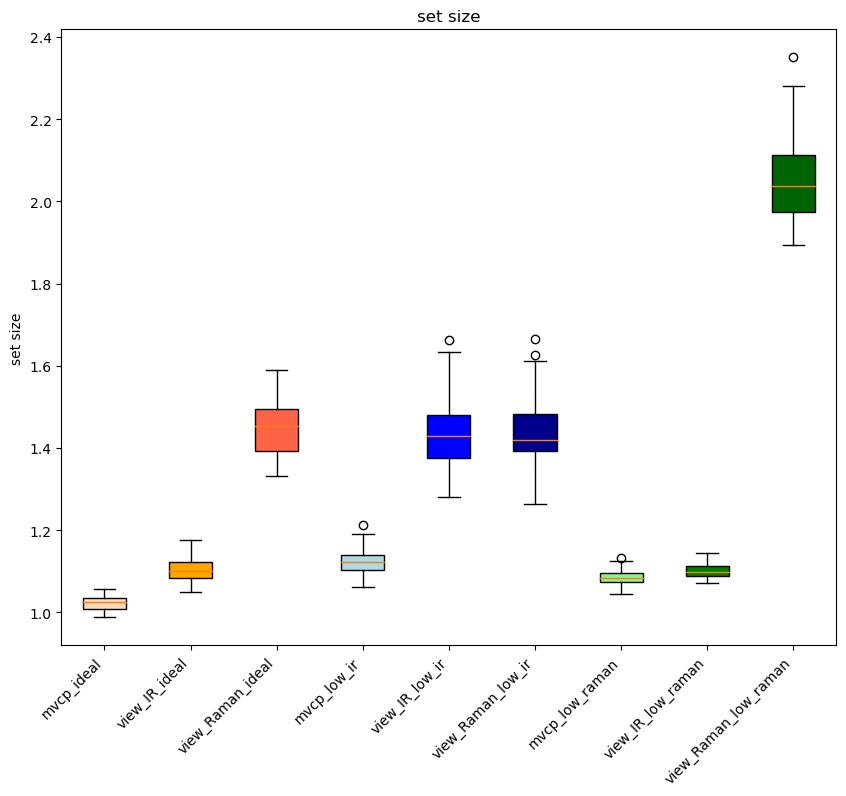

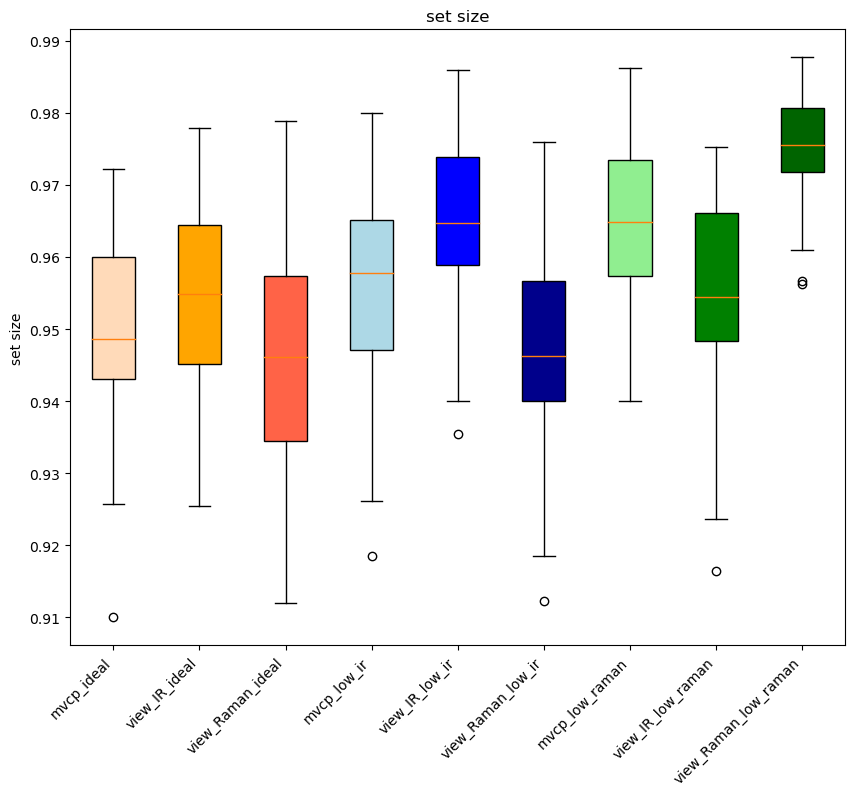

In [245]:
labels = ['mvcp_ideal', 
          'view_IR_ideal', 
          'view_Raman_ideal', 
          'mvcp_low_ir', 
          'view_IR_low_ir', 
          'view_Raman_low_ir', 
          'mvcp_low_raman', 
          'view_IR_low_raman', 
          'view_Raman_low_raman']

#set_size = [np.array(df_res_all_mean_lis[0][x]) for x in labels]#df_res_all_lis[0]
#emp_conf_list.append(df_res_cov_lis)
    
fig, ax = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True, figsize=(10, 8))
title = ['none', 'low', 'medium', 'high']

#labels = list(df_res_all_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato', 
          'lightblue', 'blue', 'darkblue',
          'lightgreen', 'green', 'darkgreen']

ax.set_ylabel('set size')
ax.set_title('set size')

bplot = ax.boxplot(list(np.mean(set_size_list,0)),
                   #list(np.array(set_size_list)[:,:,0].T),
                   #list(np.transpose(np.array(set_size_list),(0,2,1)).reshape(2500,9).T),
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.xticks(rotation=45, ha='right')
plt.show()


fig, ax = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True, figsize=(10, 8))
title = ['none', 'low', 'medium', 'high']




#labels = list(df_res_all_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato', 
          'lightblue', 'blue', 'darkblue',
          'lightgreen', 'green', 'darkgreen']

ax.set_ylabel('set size')
ax.set_title('set size')

bplot = ax.boxplot(list(np.mean(cov_list,0)),
                   #list(np.array(cov_list)[:,:,0].T),
                   #list(np.transpose(np.array(cov_list),(0,2,1)).reshape(2500,9).T),
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.xticks(rotation=45, ha='right')
plt.show()

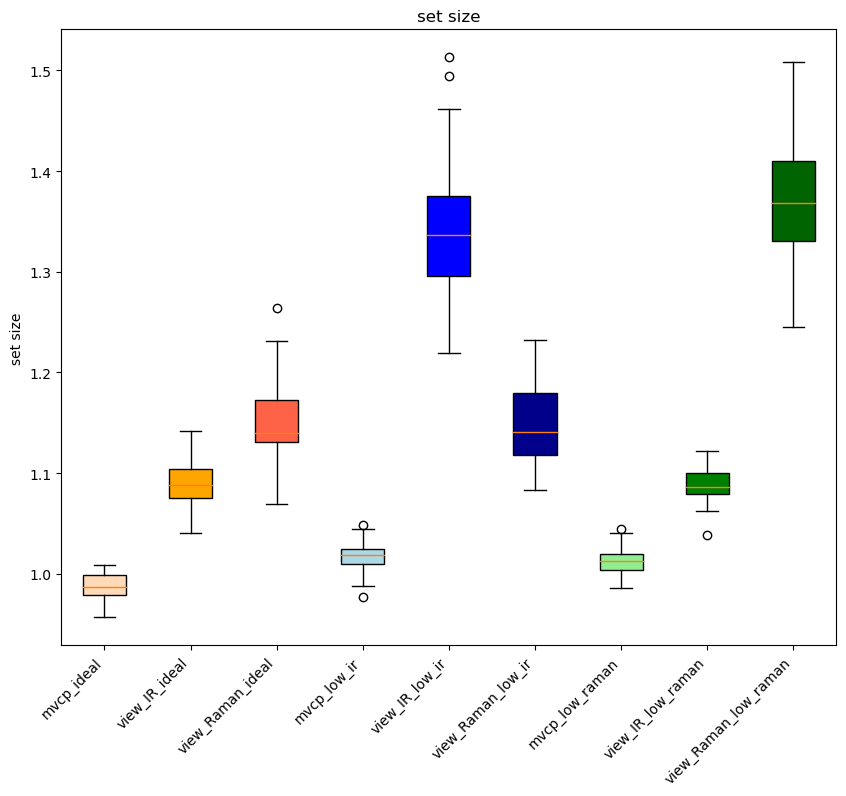

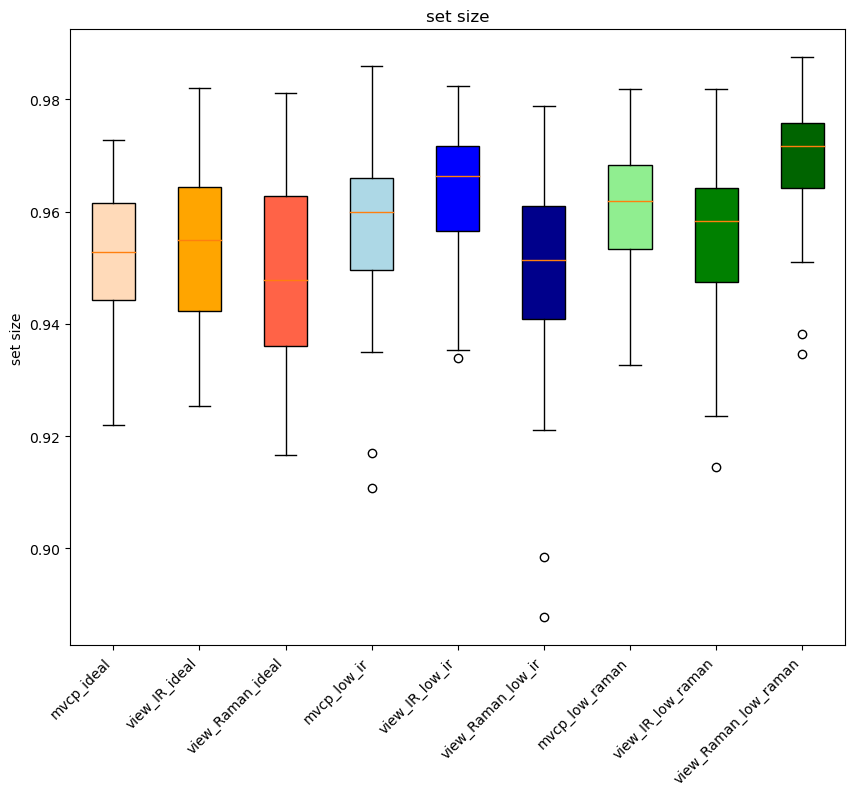

In [105]:
labels = ['mvcp_ideal', 
          'view_IR_ideal', 
          'view_Raman_ideal', 
          'mvcp_low_ir', 
          'view_IR_low_ir', 
          'view_Raman_low_ir', 
          'mvcp_low_raman', 
          'view_IR_low_raman', 
          'view_Raman_low_raman']

#set_size = [np.array(df_res_all_mean_lis[0][x]) for x in labels]#df_res_all_lis[0]
#emp_conf_list.append(df_res_cov_lis)
    
fig, ax = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True, figsize=(10, 8))
title = ['none', 'low', 'medium', 'high']

#labels = list(df_res_all_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato', 
          'lightblue', 'blue', 'darkblue',
          'lightgreen', 'green', 'darkgreen']

ax.set_ylabel('set size')
ax.set_title('set size')

bplot = ax.boxplot(list(np.mean(set_size_list,0)),
                   #list(np.array(set_size_list)[:,:,0].T),
                   #list(np.transpose(np.array(set_size_list),(0,2,1)).reshape(2500,9).T),
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.xticks(rotation=45, ha='right')
plt.show()


fig, ax = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True, figsize=(10, 8))
title = ['none', 'low', 'medium', 'high']




#labels = list(df_res_all_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato', 
          'lightblue', 'blue', 'darkblue',
          'lightgreen', 'green', 'darkgreen']

ax.set_ylabel('set size')
ax.set_title('set size')

bplot = ax.boxplot(list(np.mean(cov_list,0)),
                   #list(np.array(cov_list)[:,:,0].T),
                   #list(np.transpose(np.array(cov_list),(0,2,1)).reshape(2500,9).T),
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.xticks(rotation=45, ha='right')
plt.show()

In [111]:
set_size = list(np.mean(set_size_list,0))
cov = list(np.mean(cov_list,0))

In [116]:
set_size_df = pd.DataFrame(set_size).T
set_size_df.columns = ["set size "+x for x in labels]
cov_df = pd.DataFrame(cov).T
cov_df.columns = ["confidence "+x for x in labels]


In [276]:
set_size_df = pd.DataFrame(set_size).T
set_size_df.columns = ["set size "+x for x in labels]
cov_df = pd.DataFrame(cov).T
cov_df.columns = ["confidence "+x for x in labels]
pd.concat([set_size_df,cov_df], axis=1).to_csv('results/data_fig_3a_noise_IR.csv')

# 3b

In [237]:
IR_spectra_all = pd.concat([IR_spectra_mix_std_ideal, IR_spectra_mix_ideal,
                            IR_spectra_mix_std_lq, IR_spectra_mix_lq], axis=0).reset_index(drop=True)

Raman_spectra_all = pd.concat([Raman_spectra_mix_std_ideal, Raman_spectra_mix_ideal,
                               Raman_spectra_mix_std_lq, Raman_spectra_mix_lq], axis=0).reset_index(drop=True)
wn = np.array(Raman_spectra_all.columns[:-4])

x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table = process_data(rebecca_data_ir, 
                                                                                                         rebecca_data_raman, 
                                                                                                         IR_spectra_all,
                                                                                                         Raman_spectra_all)

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_rest, Raman_spectra_mix_rest)

quality = np.array(['ideal']*(IR_spectra_mix_std_ideal.shape[0] + IR_spectra_mix_ideal.shape[0])+ 
                   ['low']*(IR_spectra_mix_std_lq.shape[0] + IR_spectra_mix_lq.shape[0]))

smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

print(np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman))
print(np.nanmean(np.argmin(score_list[0][quality=='ideal'], 1) == label_ir[quality=='ideal']), np.nanmean(np.argmin(score_list[1][quality=='ideal'], 1) == label_raman[quality=='ideal']))
print(np.nanmean(np.argmin(score_list[0][quality=='low'], 1) == label_ir[quality=='low']), np.nanmean(np.argmin(score_list[1][quality=='low'], 1) == label_raman[quality=='low']))


0.8169811320754717 0.8264150943396227
0.9314641744548287 0.9034267912772586
0.6411483253588517 0.7081339712918661


In [159]:
IR_spectra_all = pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True)

Raman_spectra_all = pd.concat([Raman_spectra_mix_std, Raman_spectra_mix], axis=0).reset_index(drop=True)
wn = np.array(Raman_spectra_all.columns[:-4])

x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table = process_data(rebecca_data_ir, 
                                                                                                         rebecca_data_raman, 
                                                                                                         IR_spectra_all,
                                                                                                         Raman_spectra_all)

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_rest, Raman_spectra_mix_rest)

quality = np.array(['ideal']*(IR_spectra_mix_std_ideal.shape[0] + IR_spectra_mix_ideal.shape[0])+ 
                   ['low_ir']*(IR_spectra_mix_std_lq.shape[0] + IR_spectra_mix_lq.shape[0]))

smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

print(np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman))
print(np.nanmean(np.argmin(score_list[0][quality=='ideal'], 1) == label_ir[quality=='ideal']), np.nanmean(np.argmin(score_list[1][quality=='ideal'], 1) == label_raman[quality=='ideal']))
print(np.nanmean(np.argmin(score_list[0][quality=='low_ir'], 1) == label_ir[quality=='low_ir']), np.nanmean(np.argmin(score_list[1][quality=='low_ir'], 1) == label_raman[quality=='low_ir']))


0.8169811320754717 0.8264150943396227
0.838006230529595 0.8286604361370716
0.784688995215311 0.8229665071770335


In [227]:
top_hqi_values = 1-pd.DataFrame(np.concatenate(score_list, axis=1))
top_hqi_values.columns = [x + ' (IR)' for x in label_table['polymer']] + [x + ' (Raman)' for x in label_table['polymer']]
top_hqi_values = pd.concat([top_hqi_values, IR_spectra_all.iloc[:,-6:-1]], axis=1)
top_hqi_values['quality'] = quality
top_hqi_values#.to_csv('results_final/data_fig_2_top_hqi_values.csv')

,NH2SO4 (IR),NaNO3 (IR),PE (IR),PP (IR),PSL (IR),sucrose (IR),NH2SO4 (Raman),NaNO3 (Raman),PE (Raman),PP (Raman),PSL (Raman),sucrose (Raman),polymer_raman,polymer_ir,comments,polymer,id,quality
0,0.966998,0.581329,0.681163,0.683443,0.658082,0.742312,0.963210,0.739561,0.741958,0.765837,0.758097,0.764716,AS,AS,NaN,NH2SO4,mix_std_1,ideal
1,0.843685,0.549114,0.783087,0.788978,0.758956,0.942865,0.705674,0.725368,0.785470,0.846621,0.772617,0.941709,SCR,SCR,NaN,sucrose,mix_std_2,ideal
2,0.979663,0.588584,0.511633,0.524990,0.535494,0.614649,0.966600,0.727032,0.711675,0.744999,0.739757,0.739642,AS,AS,NaN,NH2SO4,mix_std_7,ideal
3,0.975891,0.583240,0.612233,0.627460,0.601026,0.663803,0.990630,0.328109,0.314022,0.336274,0.337770,0.345689,AS,AS,NaN,NH2SO4,mix_std_8,ideal
4,0.798544,0.472632,0.683477,0.681553,0.642794,0.956522,0.291818,0.319276,0.425771,0.558387,0.361575,0.982985,SCR,SCR,NaN,sucrose,mix_std_10,ideal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,0.897830,0.880343,0.905626,0.902881,0.904042,0.899608,0.830510,0.832223,0.874168,0.908185,0.901374,0.874170,PSL,LOW,NaN,PSL,mix_629,low
526,0.903498,0.905156,0.888969,0.887562,0.900702,0.904518,0.837454,0.837509,0.863230,0.894501,0.914210,0.873199,PSL,LOW,NaN,PSL,mix_631,low
527,0.865521,0.807955,0.917556,0.886493,0.890277,0.867103,0.805898,0.812482,0.917821,0.889929,0.863876,0.864497,LDPE,LOW,NaN,PE,mix_634,low
528,0.897562,0.900696,0.902329,0.906258,0.903397,0.899780,0.829959,0.833579,0.881291,0.894358,0.914328,0.886763,PSL,LOW,NaN,PSL,mix_648,low


In [224]:
pd.concat([IR_spectra_all.iloc[:,[-3,-2]],
           pd.DataFrame({'quality':quality}),
           pd.DataFrame(1-smx_all_IR, columns=["HQI IR_"+x for x in np.array(label_table.iloc[:,1])]) ,
           pd.DataFrame(1-smx_all_Raman, columns=["(HQI) Raman_"+x for x in np.array(label_table.iloc[:,1])])], axis=1)#.to_csv('results/hqi_ideal_low_Q_data_fig_3b.csv')


,polymer,id,quality,(HQI) IR_NH2SO4,(HQI) IR_NaNO3,(HQI) IR_PE,(HQI) IR_PP,(HQI) IR_PSL,(HQI) IR_sucrose,(HQI) Raman_NH2SO4,(HQI) Raman_NaNO3,(HQI) Raman_PE,(HQI) Raman_PP,(HQI) Raman_PSL,(HQI) Raman_sucrose
0,NH2SO4,mix_std_1,ideal,0.966998,0.581329,0.681163,0.683443,0.658082,0.742312,0.963210,0.739561,0.741958,0.765837,0.758097,0.764716
1,sucrose,mix_std_2,ideal,0.843685,0.549114,0.783087,0.788978,0.758956,0.942865,0.705674,0.725368,0.785470,0.846621,0.772617,0.941709
2,NH2SO4,mix_std_7,ideal,0.979663,0.588584,0.511633,0.524990,0.535494,0.614649,0.966600,0.727032,0.711675,0.744999,0.739757,0.739642
3,NH2SO4,mix_std_8,ideal,0.975891,0.583240,0.612233,0.627460,0.601026,0.663803,0.990630,0.328109,0.314022,0.336274,0.337770,0.345689
4,sucrose,mix_std_10,ideal,0.798544,0.472632,0.683477,0.681553,0.642794,0.956522,0.291818,0.319276,0.425771,0.558387,0.361575,0.982985
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,PSL,mix_629,low,0.897830,0.880343,0.905626,0.902881,0.904042,0.899608,0.830510,0.832223,0.874168,0.908185,0.901374,0.874170
526,PSL,mix_631,low,0.903498,0.905156,0.888969,0.887562,0.900702,0.904518,0.837454,0.837509,0.863230,0.894501,0.914210,0.873199
527,PE,mix_634,low,0.865521,0.807955,0.917556,0.886493,0.890277,0.867103,0.805898,0.812482,0.917821,0.889929,0.863876,0.864497
528,PSL,mix_648,low,0.897562,0.900696,0.902329,0.906258,0.903397,0.899780,0.829959,0.833579,0.881291,0.894358,0.914328,0.886763


In [47]:
env_data_95 = pd.DataFrame(env_list[5][0]).T
env_data_95.columns = ['x','y']
env_data_95.to_csv('results/envelope_95_data_fig_3b.csv')
env_data_95

,x,y
0,0.024234,0.137551
1,0.025609,0.137543
2,0.026074,0.137540
3,0.027492,0.137532
4,0.029496,0.137520
...,...,...
335,0.164164,0.047135
336,0.164171,0.045841
337,0.164184,0.043472
338,0.164184,0.043472


In [42]:
cal_data = pd.DataFrame(cal_smx_arr.T)
cal_data.columns = ['IR', 'Raman']
cal_data.to_csv('results/calibration_data_fig_3b.csv')
cal_data

,IR,Raman
0,0.033002,0.035645
1,0.057135,0.060254
2,0.020337,0.029489
3,0.024109,0.009944
4,0.043478,0.041146
...,...,...
335,0.084883,0.071049
336,0.099171,0.050452
337,0.121374,0.097892
338,0.116354,0.106471


In [197]:
#bad_examples = [31, 139, 140, 143, 150, 157, 158, 164, 165, 172, 179, 180]
#id_ = 180 
#quality.shape#.iloc[bad_examples,:]

360 PE


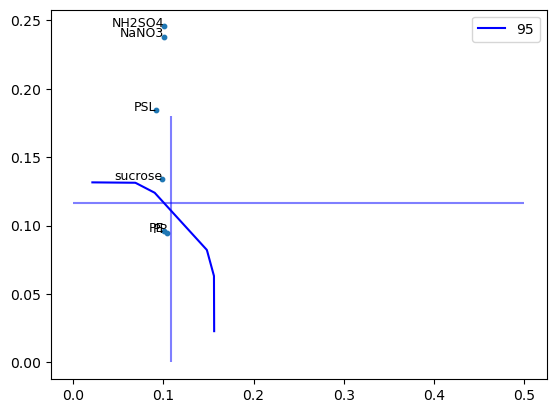

438 PP


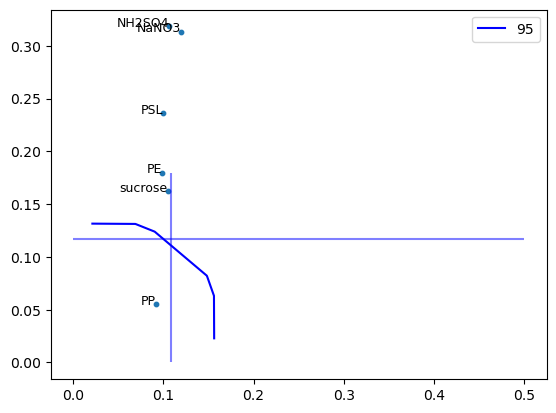

414 PSL


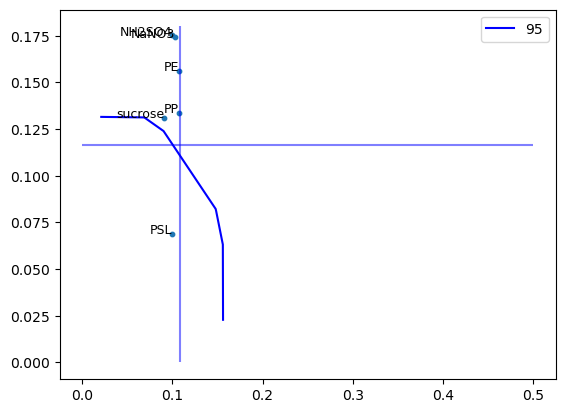

465 PE


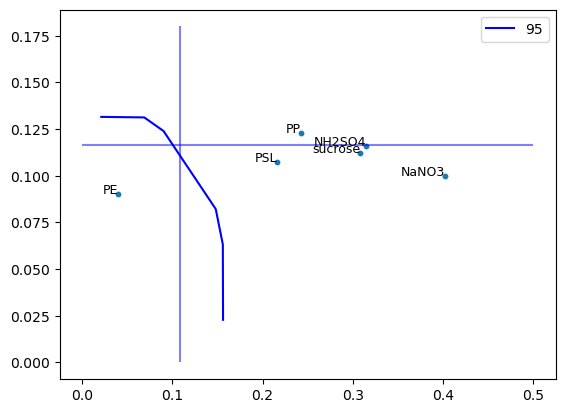

417 PP


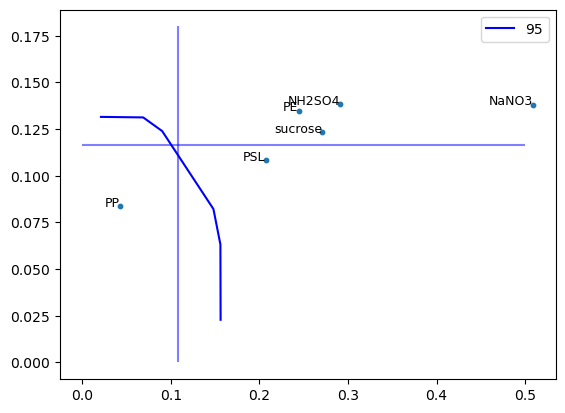

421 PSL


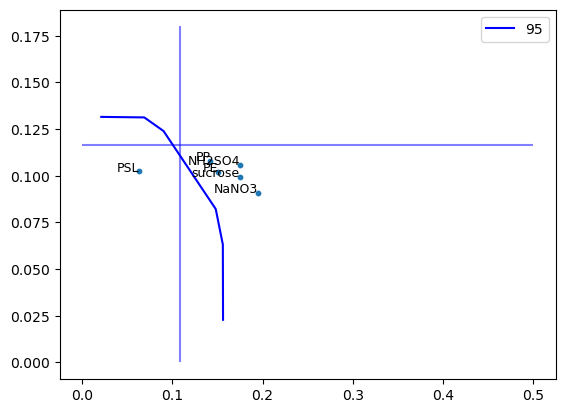

In [238]:
#bad_examples = [356, 358, 360, 411, 412, 414, 415, 417, 419, 420, 421, 422, 423, 424, 440, 465]#[31, 139, 140, 143, 150, 157, 158, 164, 165, 172, 179, 180]
bad_examples = [360, 438, 414, 465, 417, 421]

color = ['blue', 'orange', 'green', 'red', 'purple']
color = {env:x for env, x in zip(list(env_list.keys()), color)}
for j in bad_examples:#range(score_list[0].shape[0]): #
    #if label_table.iloc[label_ir[j],1] not in ["PP"] or quality[j]=="ideal":
    #    continue
    print(j, label_table.iloc[label_ir[j],1])
    plt.scatter(score_list[0][j, :],
                score_list[1][j, :], s=10)
    for i in range(6):
        plt.text(score_list[0][j, i], 
                 score_list[1][j, i], label_table.iloc[i,1], fontsize=9, ha='right')

    for env in env_list:
        env_data = pd.DataFrame(np.array(env_list[env][0]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(env_data['x - '+str(100-env)],
                     env_data['y - '+str(100-env)], label=str(100-env),
                     color=color[env])

        plt.vlines(q_ir_list[env],0, .18, alpha=.5, color=color[env])
        plt.hlines(q_raman_list[env],0, .5, alpha=.5, color=color[env])
        
    _ = plt.legend() 
    _ = plt.show()

In [200]:
IR_spectra_all.iloc[bad_examples,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
360,-1.858163,0.530297,2.348643,1.245871,0.131951,-0.210527,0.305258,-0.155265,-0.445633,0.468599,...,-2.856548,-5.539007,0,0,LDPE,LOW,NaN,PE,mix_std_199,background
411,-0.947125,-0.940717,-0.927553,-0.927260,-0.927903,-0.920529,-0.914043,-0.909394,-0.900756,-0.888830,...,-0.172849,-0.199851,0,0,LDPE,LDPE,NaN,PE,mix_20,no_background
414,-1.394509,-0.244149,-1.276649,-2.346221,-0.844417,-0.423171,-0.283760,0.176457,-0.677024,-1.264504,...,-4.967729,-0.868983,0,0,PSL,LOW,NaN,PSL,mix_31,background
419,-0.831588,-2.288933,-1.558101,-0.504529,-0.164850,0.654138,1.305220,1.172676,1.244254,0.697926,...,0.595228,-1.084989,0,0,PSL,LOW,NaN,PSL,mix_62,background
417,-0.785668,-0.584810,-0.498619,-0.467767,-0.201088,-0.051029,-0.204622,-0.264401,-0.246474,-0.337058,...,1.233706,0.280721,0,0,UNS,PP,FLUORESCENCE,PP,mix_43,no_background
421,-0.756303,-0.858353,-0.883272,-0.854919,-0.910558,-0.831358,-0.694967,-0.748041,-0.807883,-0.765564,...,-1.501765,-0.960666,0,0,PSL,PSL,"FLUORESCENCE, SOME RAMAN PEAKS SHOWING PSL",PSL,mix_71,no_background
465,-0.061764,-0.063746,-0.103635,-0.189918,-0.234658,-0.229095,-0.222510,-0.225034,-0.226038,-0.206995,...,0.023082,0.053633,0,0,LDPE,LDPE,FLUORESCENCE,PE,mix_338,no_background


In [235]:
example_id

'mix_446'

In [255]:
bad_examples

[360, 438, 414, 465, 417, 421]

In [241]:

pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[bad_examples,-2]

360    mix_321
438    mix_477
414    mix_434
465    mix_530
417    mix_438
421    mix_446
Name: id, dtype: object

In [254]:
id_ = bad_examples[0]
pd.DataFrame(np.array([score_list[0][id_:id_+1], score_list[1][id_:id_+1]] )[:,0,:].T)
#score_list[0][id_:id_+1]

,0,1
0,0.100963,0.245441
1,0.100641,0.238017
2,0.100231,0.095698
3,0.104234,0.094630
4,0.092023,0.184090
5,0.098404,0.133815


mix_321


  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE', 'PP']
IR ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']
Raman ['PE', 'PP']


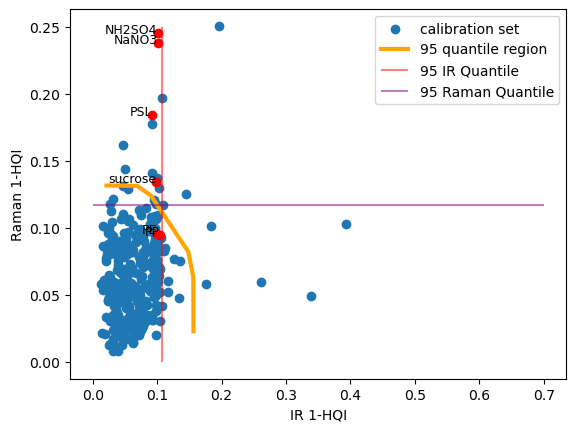

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  3.28it/s]


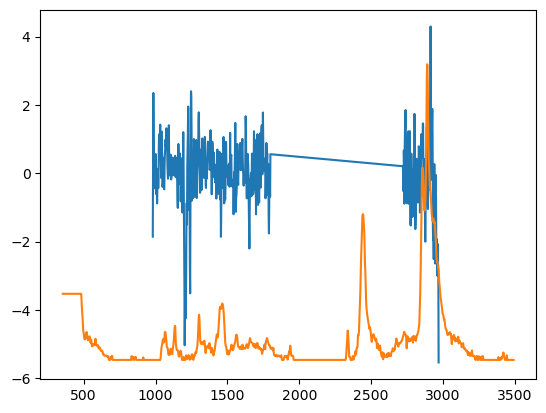

mix_477


  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PP']
IR ['NH2SO4', 'PE', 'PP', 'PSL', 'sucrose']
Raman ['PP']


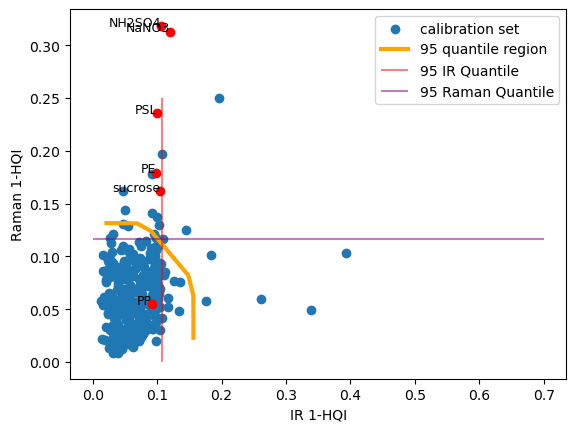

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  3.30it/s]


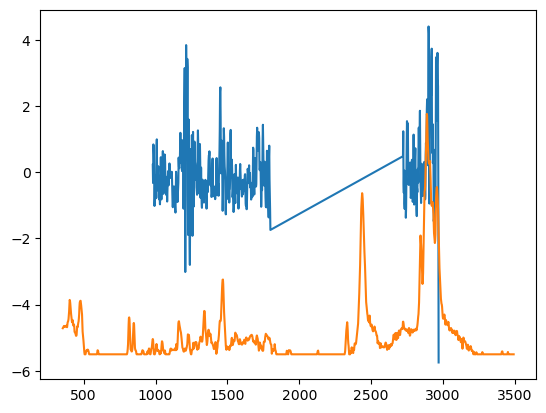

mix_434


  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']
Raman ['PSL']


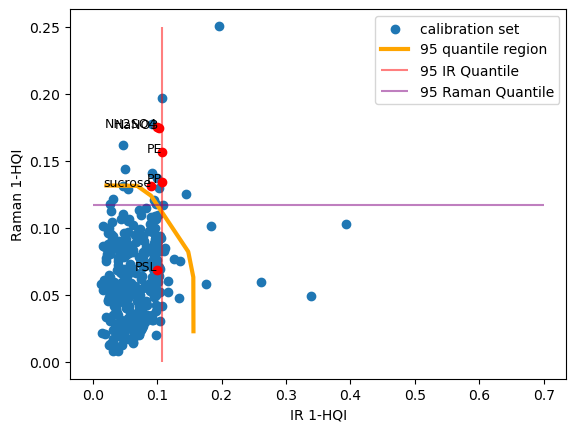

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  3.26it/s]


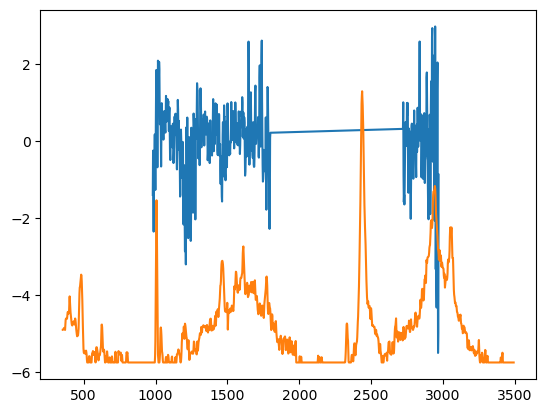

mix_530


  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['NH2SO4', 'NaNO3', 'PE', 'PSL', 'sucrose']


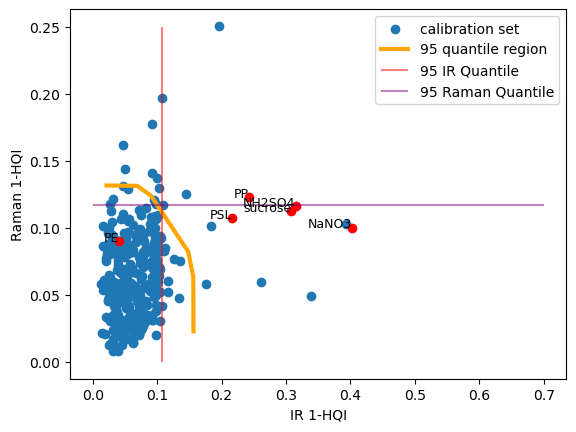

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  3.26it/s]


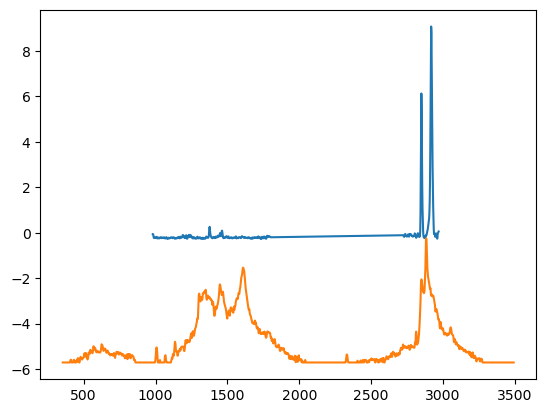

mix_438


  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PP']
IR ['PP']
Raman ['PP', 'PSL']


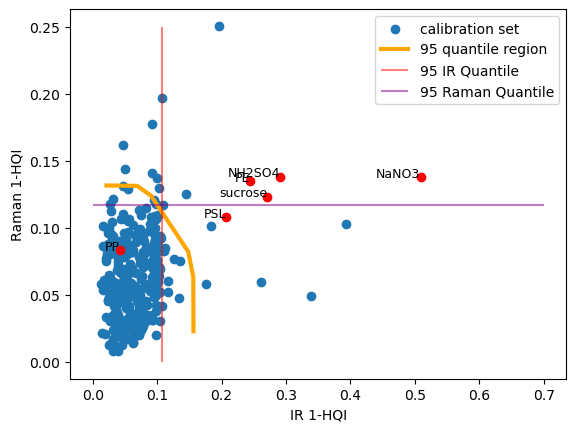

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  3.35it/s]


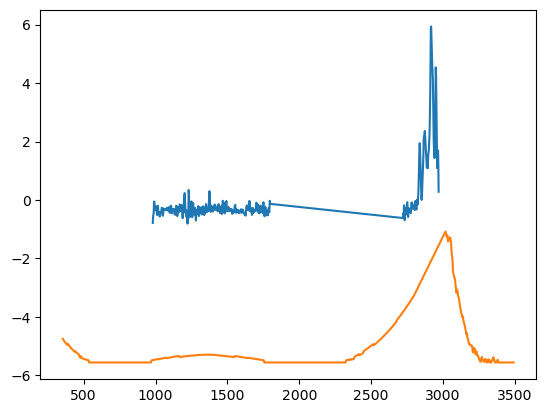

mix_446


  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']


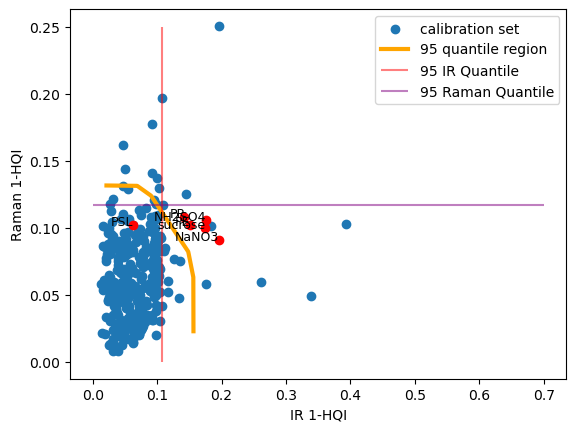

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  2.53it/s]


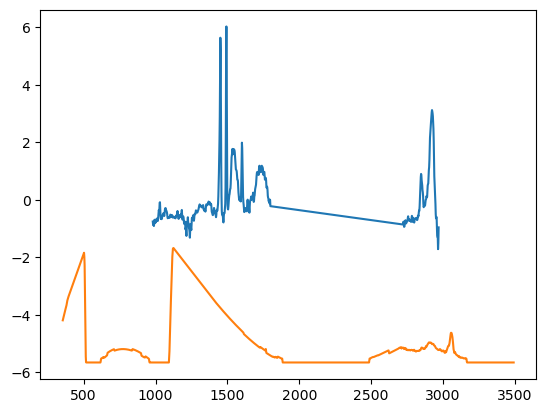

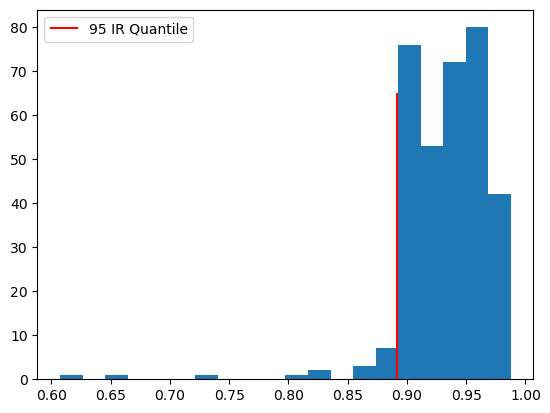

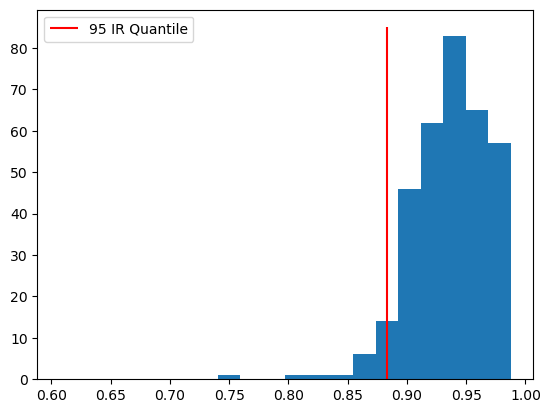

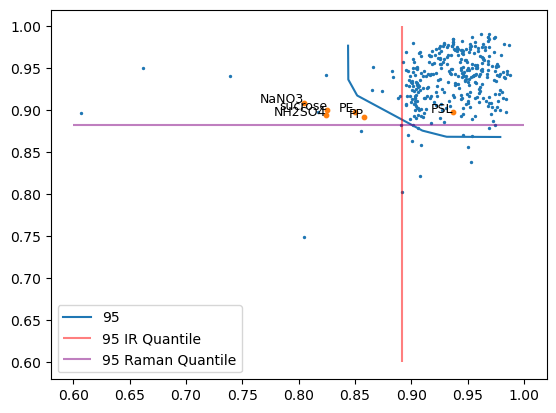

,x - 95,y - 95
0,0.978812,0.868436
1,0.975524,0.868455
2,0.972192,0.868475
3,0.971776,0.868477
4,0.970824,0.868483
...,...,...
334,0.843835,0.964208
335,0.843833,0.964539
336,0.843826,0.965835
337,0.843815,0.967964


In [242]:
id_ = bad_examples[5]
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] 

for id_ in bad_examples:
    example_id = pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[id_,-2]
    score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] 
    print(example_id)
    (ps_list, 
     ps_ir_list, 
     ps_raman_list, 
     env_list, 
     cal_smx_arr, 
     q_ir_list, 
     q_raman_list) = envelop(score_list, 
                             label_ir, score_example,
                             alphas=[0.05],
                             N_sim=1, 
                             quant_prop=.2, 
                             cal_prop=0.8, 
                             seed_init=10)
    
    hqi_ex = pd.DataFrame({'polymer':label_table['polymer'],
              'HQI (IR)':1-score_example[0][0], 
              'HQI (Raman)':1-score_example[1][0]})
    hqi_ex#.to_csv('results_final/data_fig_1_hqi_example_id_'+str(example_id)+'.csv')

    pred_sets_ex = pd.concat([(pd.DataFrame(ps_list).T), 
                              (pd.DataFrame(ps_ir_list).T),
                              (pd.DataFrame(ps_raman_list).T)],axis=1).reset_index()
    
    pred_sets_ex['index'] = 100 - pred_sets_ex['index']
    pred_sets_ex.columns = ['confidence', 'MVCP (IR + Raman)', 'CP (IR)', 'CP (Raman)']
    pred_sets_ex#.to_csv('results_final/data_fig_3_pred_sets_id_'+str(example_id)+'.csv')
    
    _ = plt.show()
    _ = plt.plot(IR_spectra_all.iloc[id_:id_+1,:-8].T)
    _ = plt.plot(Raman_spectra_all.iloc[id_:id_+1,:-8].T-5)
    _ = plt.show()
    

h_ir = plt.hist(1-cal_smx_arr[0],bins=20, density=False)
_ = plt.vlines(x= 1-q_ir_list[5][0],
                ymin=0,
                ymax=65,
                colors='red',
                alpha=1,
                linestyles='solid',
                label='95 IR Quantile')
_ = plt.legend()
_ = plt.show()

h_raman = plt.hist(1-cal_smx_arr[1],bins=h_ir[1], density=False)
_ = plt.vlines(x=1- q_raman_list[5][0],
                ymin=0,
                ymax=85,
                colors='red',
                alpha=1,
                linestyles='solid',
                label='95 IR Quantile')
_ = plt.legend()
_ = plt.show()

pd.DataFrame({'HQI':h_ir[1][:-1], 
              '# IR':h_ir[0],
              '# Raman':h_raman[0]
              })#.to_csv('results_final/data_fig_3a_histograms.csv')


plt.scatter(1-cal_smx_arr[0],
            1-cal_smx_arr[1], s=2)

plt.scatter(1-score_example[0],
            1-score_example[1], s=10)

for i in range(6):
    plt.text(1-score_example[0][0, i], 
             1-score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')
    
env_data_list = []
for env in env_list:
    env_data = pd.DataFrame(1-np.array(env_list[env][0]).T)
    env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
    _ = plt.plot(env_data['x - '+str(100-env)],
                 env_data['y - '+str(100-env)], label=str(100-env))
    env_data_list.append(env_data)
    
_ = plt.vlines(x= 1-q_ir_list[5][0],
                ymin=.6,
                ymax=1,
                colors='r',
                alpha=.5,
                linestyles='solid',
                label='95 IR Quantile')

_ = plt.hlines(y= 1-q_raman_list[5][0],
                            xmin=.6,
                            xmax=1,
                            colors='purple',
                            alpha=.5,
                            linestyles='solid',
                            label='95 Raman Quantile')

_ = plt.legend()
_ = plt.show()

cal_data = pd.DataFrame(1-cal_smx_arr.T)
cal_data.columns = ['IR', 'Raman']
cal_data#.to_csv('results_final/data_fig_3_calibration.csv')

env_data = pd.concat(env_data_list,axis=1)

env_data#.to_csv('results_final/data_fig_3_envelopes.csv')



In [231]:
ps_list

defaultdict(list, {5: [['PSL']]})

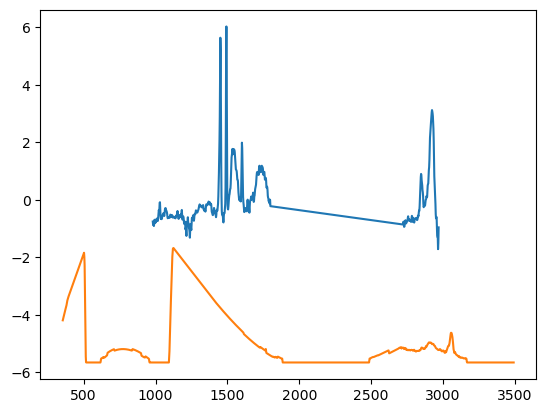

In [222]:
_ = plt.plot(IR_spectra_all.iloc[id_:id_+1,:-8].T)
_ = plt.plot(Raman_spectra_all.iloc[id_:id_+1,:-8].T-5)

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['NH2SO4']
IR ['NH2SO4']
Raman ['NH2SO4', 'NaNO3', 'PSL']


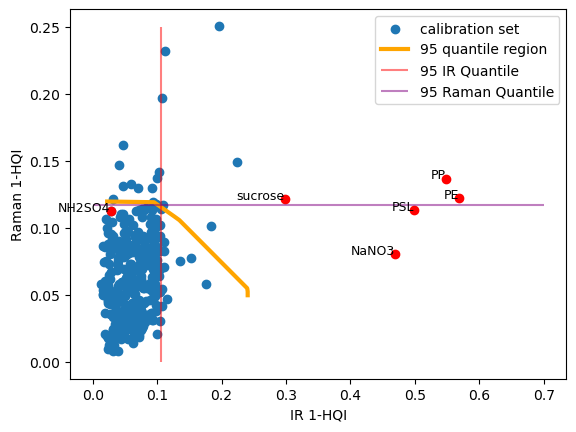

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  3.07it/s]


In [123]:
id_ = 323
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] 

ps_list, ps_ir_list, ps_raman_list, env_list, cal_smx_arr, q_ir_list, q_raman_list = envelop(score_list, label_ir, score_example,
alphas=[0.05],
#alphas=[.05],
N_sim=1, 
quant_prop=.2, 
cal_prop=0.8, 
seed_init=0)

In [128]:
IR_spectra_all.iloc[id_:id_+1,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
323,-0.639141,-0.44469,-0.316637,-0.370185,-0.506829,-0.726219,-0.673383,-0.425694,-0.320052,-0.44425,...,-0.82232,-0.723288,0,0,UNS,AS,"ODD PEAKS IN RAMAN, FLUORESCENCE",NH2SO4,mix_std_34,no_background


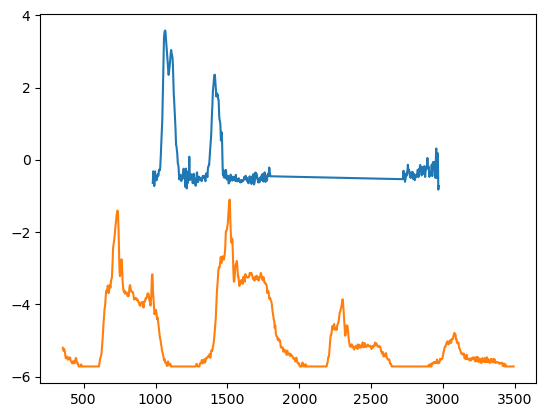

In [124]:
_ = plt.plot(IR_spectra_all.iloc[id_:id_+1,:-8].T)
_ = plt.plot(Raman_spectra_all.iloc[id_:id_+1,:-8].T-5)

In [86]:
IR_spectra_all.iloc[id_:id_+1,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
323,-0.459519,0.240444,0.764777,0.309286,-0.387325,0.135113,0.079787,-0.187471,0.244736,0.123697,...,-0.127707,-3.976646,0,0,PSL,LOW,NaN,PSL,mix_216,background
